# 21.12. Полное сравнение аппроксимаций камерной крови на исторической 4D-КТ и результаты РФФИ

**Статус:** вычислительное сравнение геометрических моделей. Цель — определить, какие формы и критерии аппроксимации сохраняют объём, положение и пофазное движение автоматической области крови. Электрическая эквивалентность и тождество исходных исследований РФФИ этим расчётом не устанавливаются.

На трёх исторических сериях 4D-КТ рассмотрено по 20 фаз. Целевая область каждой фазы — объединение четырёх масок камер крови TotalSegmentator; крупные сосуды не включены. Та же область используется для всех методов внутри каждой фазы. Исходные маски не заменены вручную, а перегородки специально не заполнены. Таким образом, полученные величины характеризуют согласие приближений с данной *автоматической* сегментацией, а не доказанную точность относительно истинной анатомии.

## Постановка и происхождение данных

Для каждой серии используются 20 исходных NIfTI-фаз и по четыре маски камер TotalSegmentator на фазу. Их контрольные суммы, физическая аффинная матрица, конфигурация методов и параметры оптимизации сохранены в локальных протоколах расчёта. Координаты выражены в миллиметрах в системе RAS+: ось x направлена вправо относительно тела, y — кпереди, z — к голове. Фронтальную траекторию образуют компоненты (Δx, Δz) относительно фазы 0%; одинаковая фаза служит началом для всех кандидатов в данной серии.

**Реестр:** автоматическая маска T0 — самосравнение; I1–I3 — преобразования индивидуальной формы первой фазы; G1–G5 (с подвариантами) — восемь сфер; L1–L4 (с подвариантами) — восемь эллипсоидов; M1–M9 — девять отдельных библиотечных подгонок MATLAB. Итого 29 представлений и 1740 пар «фаза–метод». Все 1740 пар получили численную оценку без зарегистрированных отказов; геометрическая корректность найденной формы не является свидетельством глобального минимума или физиологической пригодности. Библиотечные подгонки выполнены по одинаковым детерминированным выборкам поверхности из 8192 точек. Совпадение названия G/L и M не означает совпадения формул. Параметры кандидатов в этом опыте определяются с использованием маски соответствующей фазы: непосредственно по её геометрии или по её объёму и центру. Поэтому результат характеризует способность формы аппроксимировать известную КТ-область, а не способность восстановить неизвестное движение из электрических измерений.

Исторические контурные методы И1–И3 из РФФИ/Тихомирова **не входят в число 29 исполненных методов**. Для их строгого запуска ещё требуется установить плоскость исходного контура, подготовку области и правило задания третьей координаты. Латинские I1–I3, представленные здесь, имеют другое определение. Названия Sphere, Ellipse и MinVolEllipse в РФФИ также не отождествляются автоматически с M7–M9: точная историческая реализация и настройки этих трёх вариантов пока не подтверждены, а минимальный по объёму охватывающий эллипсоид отдельным алгоритмом в этом прогоне не вычислялся. Протоколы в `results/old_approximation_sweep_20260925/` фиксируют исходные хэши и версии алгоритмов.

## Определения вариантов

Коды указывают способ определения параметров, а не тип электродной сборки. «Фиксированный объём» означает равенство непрерывного объёма модели объёму целевой маски; «фиксированный центр» — совпадение с её центром объёма.

| Код | Геометрическое правило |
|:--|:--|
| T0 | Автоматическая маска той же фазы; внутренний ориентир сравнения. |
| I1 / I2 / I3 | Исходная индивидуальная форма первой фазы: изотропное масштабирование / жёсткий перенос-поворот с масштабированием / аффинное преобразование по моментам. |
| G1 / G2 | Сфера с центром маски и радиусом по равному объёму / по второму моменту. |
| G3a / G3b / G3c | Подгонка сферической поверхности: фиксированный центр / свободный центр / фиксированный объём. |
| G4a / G4b | Максимизация дискретного перекрытия сферы: фиксированный / свободный объём. |
| G5 | Алгебраическая подгонка сферы по точкам поверхности. |
| L1 / L2 | Эллипсоид по вторым моментам: полуоси масштабированы до объёма маски / без этого масштабирования. |
| L3a / L3b / L3c / L3d | Подгонка поверхности эллипсоида: фиксированный центр со свободным объёмом / свободные центр и объём / фиксированные центр и объём / свободный центр при фиксированном объёме. |
| L4a / L4b | Максимизация дискретного перекрытия эллипсоида со свободным центром: фиксированный / свободный объём. |
| M1–M6 | Библиотечная подгонка квадрики: BOOK, TAUB, HES, SOD, FC, 2-NORM соответственно. |
| M7 / M8 / M9 | Библиотечный эллипсоид с осями координат / со свободной ориентацией / алгебраическая сфера. |

Алгоритмические ограничения локальной оптимизации, параметры выборки и точные функции MATLAB сохранены в расчётных протоколах и исходном коде. Методы, оптимизирующие дискретное перекрытие, проверены на выбранной сетке, но сертификата глобального оптимума не имеют.

## Показатели сравнения

**Коэффициент Dice** равен удвоенному объёму пересечения приближения с маской, делённому на сумму их объёмов. Значение 1 соответствует полному совпадению на сетке исходной КТ. В расчёте эллипсоиды и сферы дискретизированы по центрам вокселей; это численная оценка перекрытия, а не точный интеграл двух непрерывных тел.

**Ошибка объёма**, % = 100 × (объём непрерывного приближения / объём целевой маски − 1). На рисунке показана медиана её абсолютного значения за 20 фаз. Малое значение этого показателя не гарантирует правильного положения или поверхности; у равновеликой сферы G1 оно равно нулю по определению.

**Смещение центра**, мм — евклидово расстояние между центром приближения и центром целевой маски в одной фазе. **Ошибка фронтального хода**, мм — среднеквадратичная за 20 фаз длина разности двух перемещений относительно их собственных центров в фазе 0%. Этот показатель сравнивает форму траектории, устраняя постоянное смещение между моделями. Нулевой ход G1/G2 при одинаковом центре не означает совпадения радиусов.

Все медианы считаются отдельно для каждой серии. Фазы одного человека коррелированы, поэтому 20 фаз не трактуются как 20 независимых наблюдений и здесь не приводятся фиктивные доверительные интервалы.

## Рисунок 1. Полная матрица геометрического соответствия

Каждая строка — один зарегистрированный метод, каждый столбец в каждой панели — одна и та же серия КТ. В ячейке напечатано численное значение; цвет помогает увидеть различия, но не заменяет числа. Для объёма и смещения цветовая шкала построена по log(1+x), чтобы крупные ошибки не скрывали различия малых; подписи и шкалы приведены в исходных единицах. Чёрные горизонтальные линии отделяют анатомические, сферические, эллипсоидальные и библиотечные представления. В рамках оценки перекрытия более высокий Dice предпочтителен; для трёх остальных показателей предпочтительны малые значения. Это **разные критерии**, и ни один из них отдельно не устанавливает качество электрического сигнала.

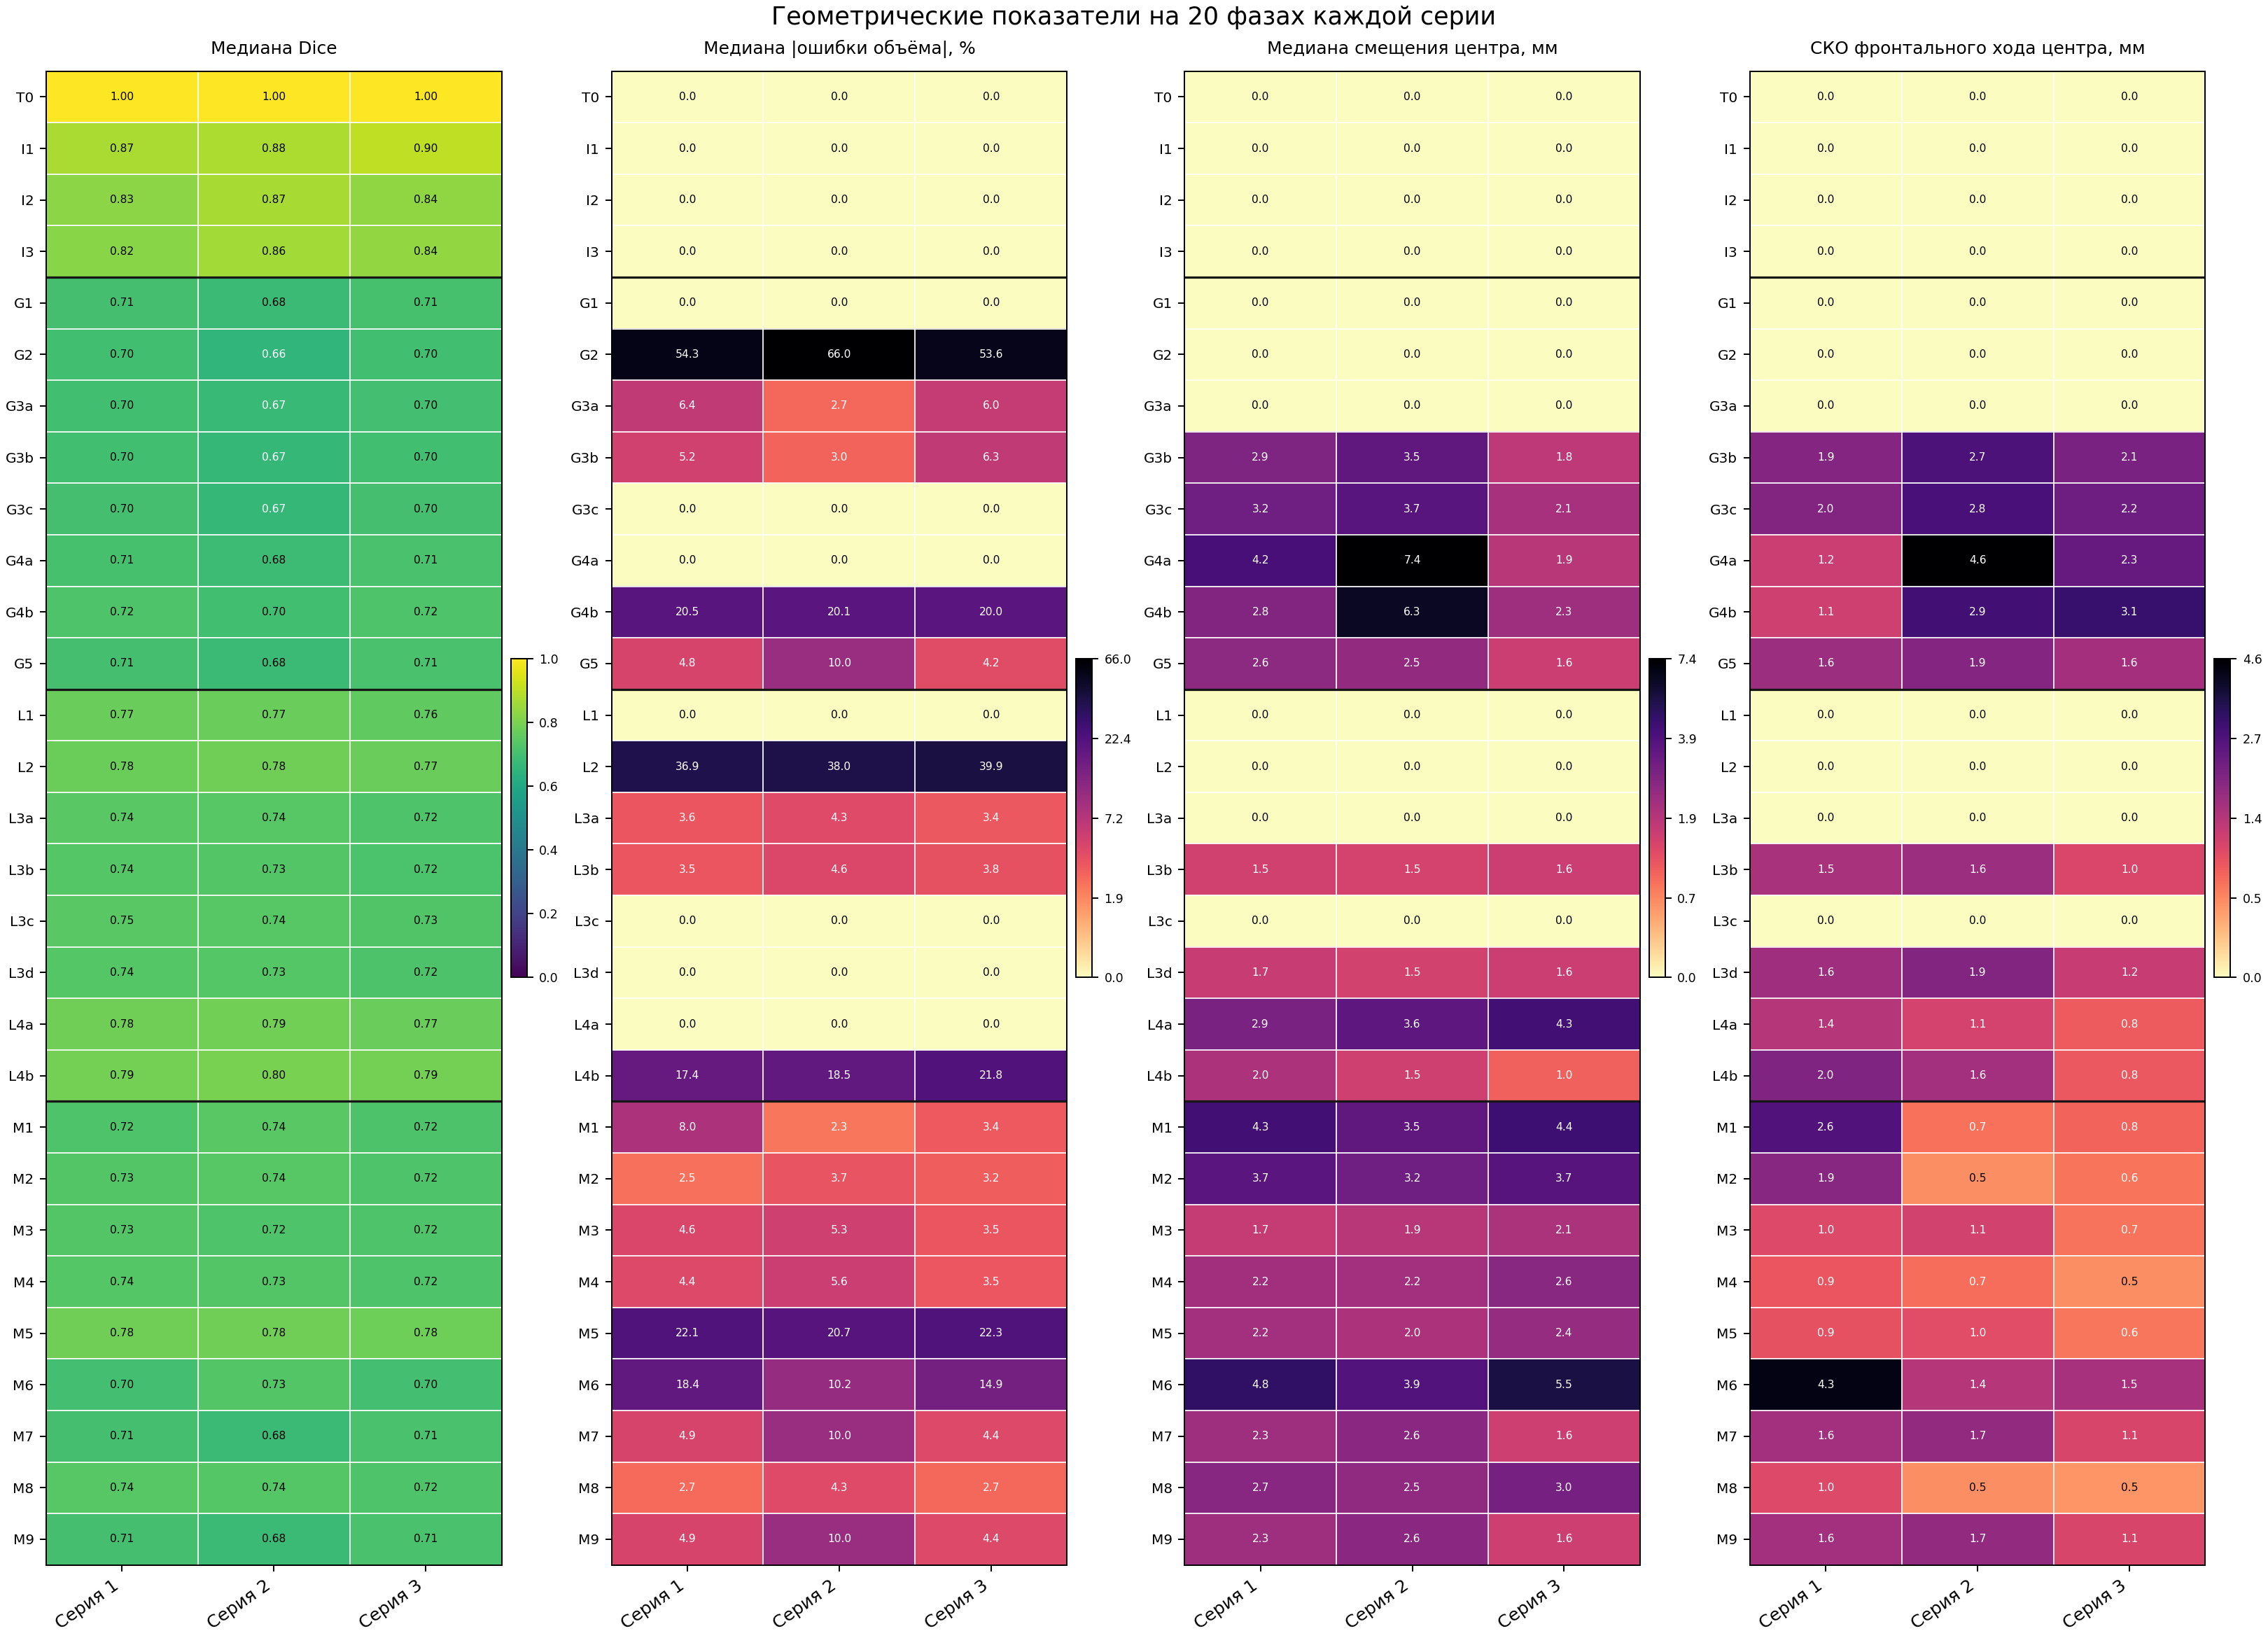

In [1]:
from IPython.display import Image, display
display(Image(filename="results/old_approximation_sweep_20260925/aggregate/figures/all_methods_matrix.png"))

Проверка всех методов на одной целевой области позволяет увидеть цену выбранного ограничения. Методы с жёстким сохранением объёма могут иметь нулевую ошибку объёма при заметной потере формы. Метод, хорошо приближающий поверхность, может смещать центр. Сравнивать следует весь набор показателей по одной фазе и по одной серии; усреднение по разным людям не заменяет такого сопоставления. Маска T0 имеет единичный Dice и нулевые ошибки **по определению** и не служит внешним анатомическим эталоном. Далее для каждого семейства указан метод с наибольшей медианой Dice по 20 фазам. Это геометрическое описание, а не выбор для электрического восстановления.

| Серия | Индивидуальная форма | Сфера | Эллипсоид | Библиотечная форма |
|:--|:--|:--|:--|:--|
| Серия 1 | I1 (0.875) | G4b (0.723) | L4b (0.792) | M5 (0.785) |
| Серия 2 | I1 (0.877) | G4b (0.699) | L4b (0.799) | M5 (0.783) |
| Серия 3 | I1 (0.905) | G4b (0.724) | L4b (0.789) | M5 (0.778) |

Во всех трёх сериях наибольший Dice среди преобразований индивидуальной формы имеет I1 (0.875 / 0.877 / 0.905); среди сфер — G4b (0.723 / 0.699 / 0.724), среди эллипсоидов — L4b (0.792 / 0.799 / 0.789), среди библиотечных методов — M5/FC (0.785 / 0.783 / 0.778). Однако медиана абсолютной ошибки объёма у G4b составляет 20.5 / 20.1 / 20.0%, у L4b — 17.4 / 18.5 / 21.8%, у M5 — 22.1 / 20.7 / 22.3%. Равновеликие G1 и L1 имеют нулевую ошибку объёма по определению, но их Dice ниже: 0.706 / 0.680 / 0.710 и 0.773 / 0.771 / 0.757 соответственно. Следовательно, лидерство по перекрытию зависит от того, допускается ли ошибка объёма; выбор следует делать по заранее заданному сочетанию геометрических и электрических критериев. Нулевое расхождение траекторий I1 и G1 с центром маски задано формулой их построения и не является независимой проверкой движения.

## Таблица 1. Dice по всем методам и сериям

Медианы по 20 фазам. Названия кодовых методов расшифрованы в реестре выше; у M1–M9 указан конкретный библиотечный алгоритм.

| Метод | Семейство | Серия 1 | Серия 2 | Серия 3 |
|:--|:--|--:|--:|--:|
| T0 | анатомическая маска | 1.000 | 1.000 | 1.000 |
| I1 | индивидуальная форма | 0.875 | 0.877 | 0.905 |
| I2 | индивидуальная форма | 0.826 | 0.867 | 0.836 |
| I3 | индивидуальная форма | 0.824 | 0.863 | 0.838 |
| G1 | сфера | 0.706 | 0.680 | 0.710 |
| G2 | сфера | 0.699 | 0.658 | 0.698 |
| G3a | сфера | 0.696 | 0.673 | 0.700 |
| G3b | сфера | 0.698 | 0.666 | 0.697 |
| G3c | сфера | 0.704 | 0.668 | 0.705 |
| G4a | сфера | 0.710 | 0.685 | 0.711 |
| G4b | сфера | 0.723 | 0.699 | 0.724 |
| G5 | сфера | 0.707 | 0.682 | 0.713 |
| L1 | эллипсоид | 0.773 | 0.771 | 0.757 |
| L2 | эллипсоид | 0.775 | 0.782 | 0.770 |
| L3a | эллипсоид | 0.744 | 0.741 | 0.725 |
| L3b | эллипсоид | 0.735 | 0.732 | 0.717 |
| L3c | эллипсоид | 0.745 | 0.742 | 0.729 |
| L3d | эллипсоид | 0.737 | 0.735 | 0.721 |
| L4a | эллипсоид | 0.782 | 0.786 | 0.770 |
| L4b | эллипсоид | 0.792 | 0.799 | 0.789 |
| M1 | BOOK | 0.724 | 0.744 | 0.723 |
| M2 | TAUB | 0.734 | 0.742 | 0.723 |
| M3 | HES | 0.733 | 0.724 | 0.725 |
| M4 | SOD | 0.738 | 0.734 | 0.724 |
| M5 | FC | 0.785 | 0.783 | 0.778 |
| M6 | 2-NORM | 0.701 | 0.733 | 0.700 |
| M7 | эллипсоид xyz | 0.707 | 0.681 | 0.713 |
| M8 | эллипсоид свободный | 0.739 | 0.738 | 0.724 |
| M9 | алгебраическая сфера | 0.707 | 0.681 | 0.713 |

## Рисунок 2. Примеры траекторий центра

Для читаемости показаны заранее заданные представители семейств: T0, G4b, L4b, M1/BOOK, M5/FC и M9. Все 29 методов, включая не показанные отдельными линиями, представлены в последней панели рисунка 1 и в числовой таблице `trajectories.csv`. Все кривые приведены к собственному центру в фазе 0%, а не искусственно совмещены по оптимальной регистрации. Идентичные или почти идентичные траектории могут накладываться друг на друга. Направления осей соответствуют КТ RAS+, а не схеме координат РФФИ.

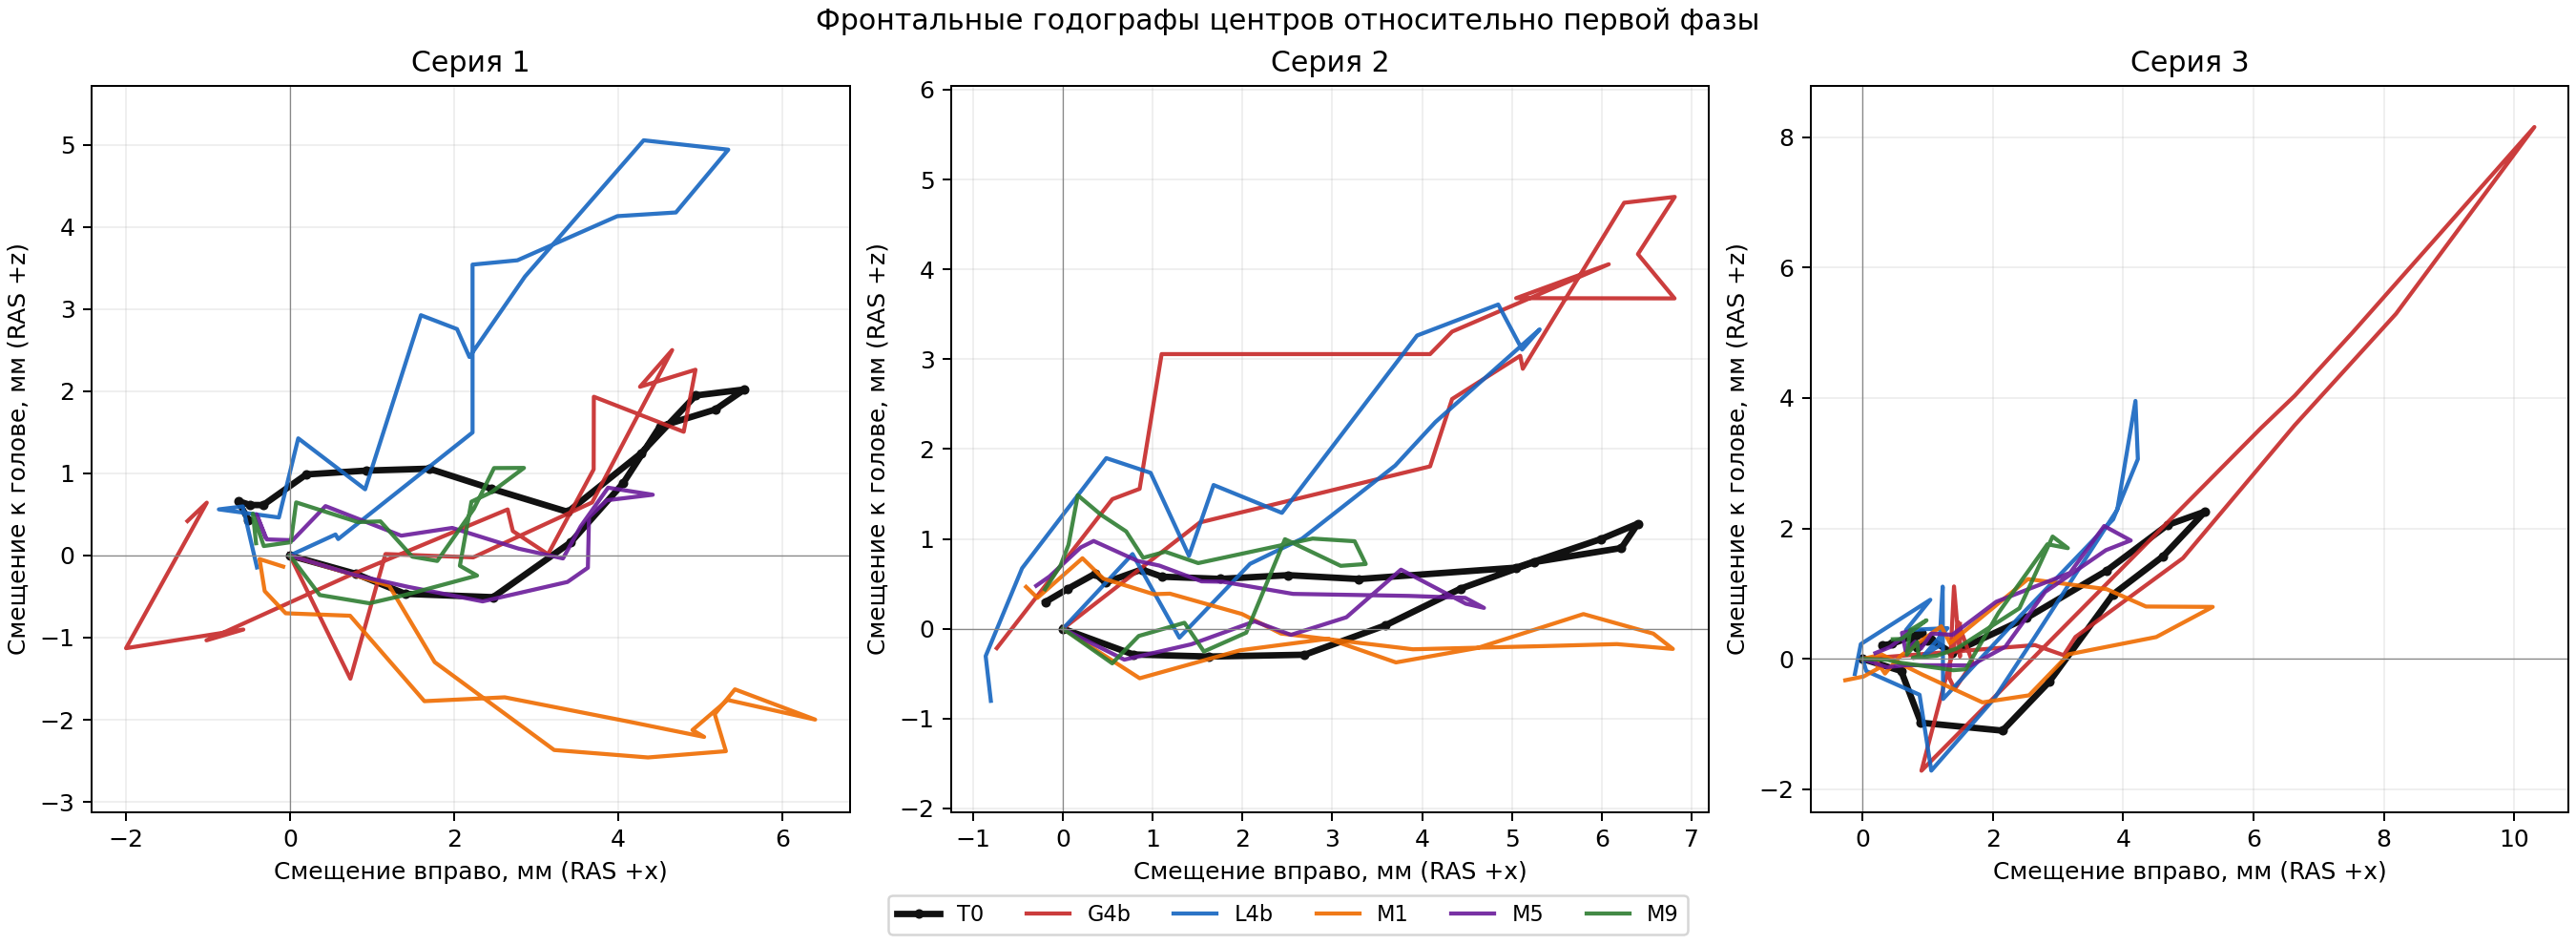

In [1]:
from IPython.display import Image, display
display(Image(filename="results/old_approximation_sweep_20260925/aggregate/figures/selected_frontal_hodographs.png"))

Для автоматической маски максимальное фронтальное удаление центра от первой фазы равно 5.9 / 6.5 / 5.7 мм по трём сериям. Среднеквадратичная ошибка фронтального перемещения относительно этой маски у G4b составляет 1.1 / 2.9 / 3.1 мм, у L4b — 2.0 / 1.6 / 0.8 мм, у BOOK/M1 — 2.6 / 0.7 / 0.8 мм. Следовательно, даже метод с лучшим перекрытием внутри семейства может воспроизводить пофазный ход центра хуже, чем предполагает его Dice. Эти отклонения получены относительно автоматической маски крови и не являются ошибкой по отношению к опубликованному электрическому годографу.

## Рисунок 3. Опубликованные электрические годографы РФФИ

Фрагменты рисунков 27, 29 и 31 источника показаны отдельно от годографов КТ. В отчёте они получены обратным расчётом по пяти каналам и сглажены. Оси рисунка соответствуют авторской системе РФФИ; её фронтальная плоскость не является плоскостью (x,y) КТ RAS+. Совпадение участников, определения сферы и фаз пока не установлено, поэтому наложение кривых и численная ошибка между ними здесь не вычисляются. Источник: «Отчёт РФФИ 2021 v2.1.pdf», PDF с. 50–53; полный хэш приведён ниже.

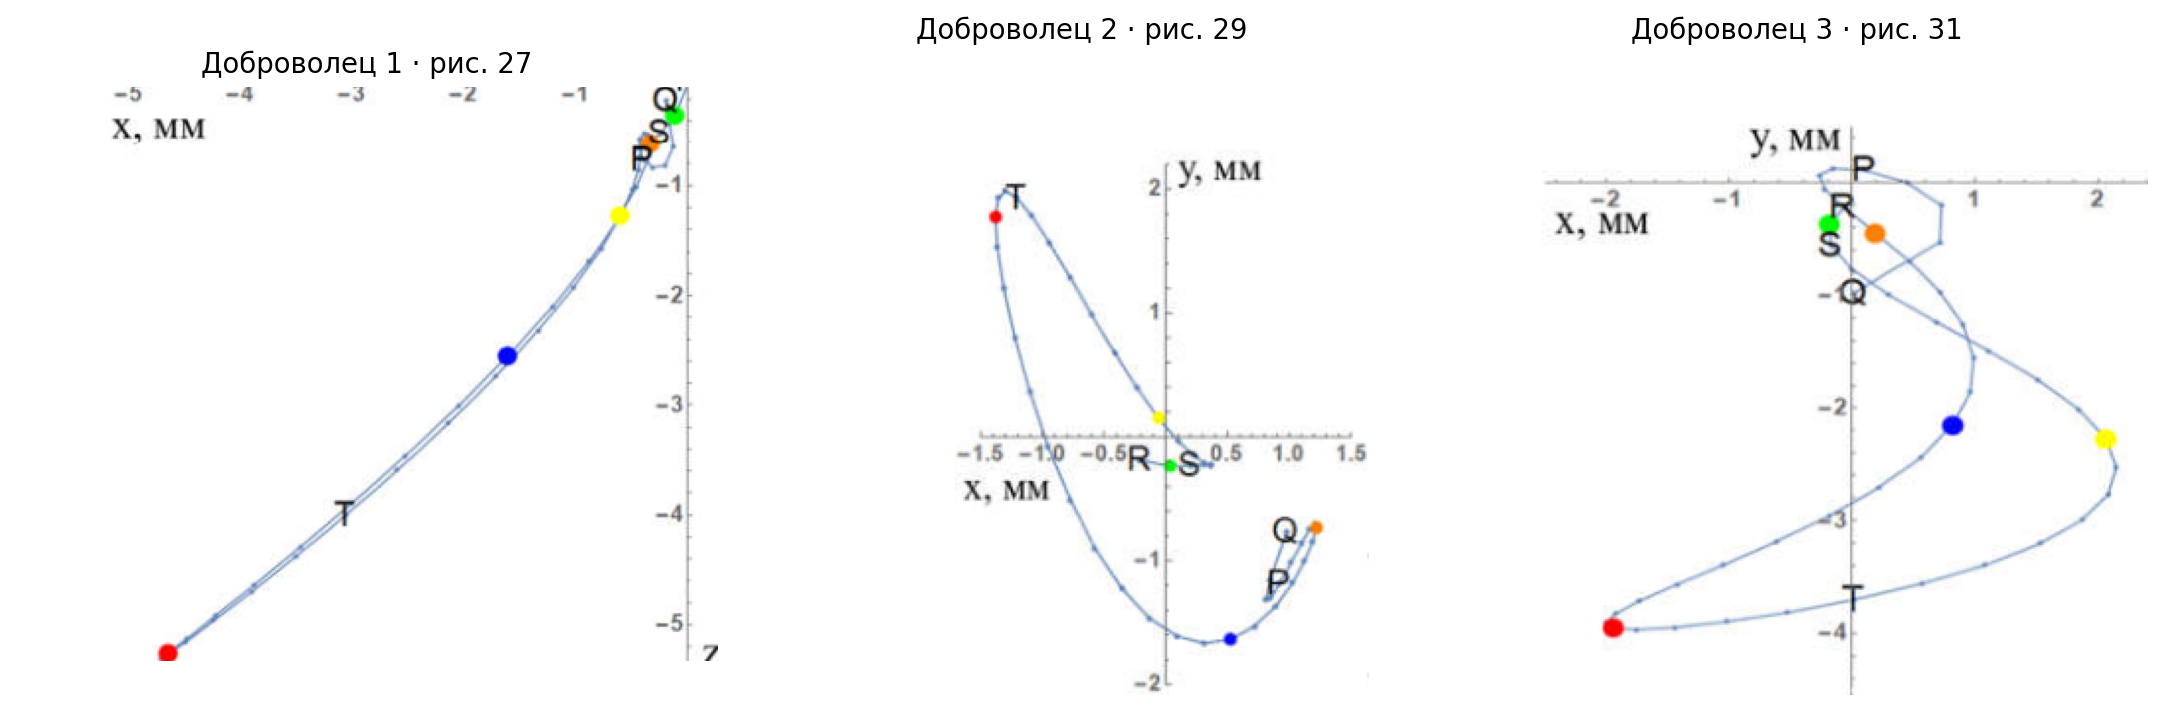

In [1]:
from IPython.display import Image, display
display(Image(filename="results/nix_cardiac_cycle_fat_20260916/rfbr_xy_hodographs.png"))

## Сопоставление с опубликованным расчётом РФФИ

В [отчёте РФФИ 2021, раздел 8.5, таблицы 23–24](zotero://open-pdf/library/items/3NAQJNXQ?page=97) девять названных методов сравнивались на моделях крови **четырёх** добровольцев при вдохе и выдохе. После заполнения перегородок двумерной операцией с окружностью радиусом 20 мм значения существенно изменились. Ниже приведены шесть методов, для которых названия совпадают с M1–M6. В двух столбцах РФФИ приведены опубликованные средние ошибки объёма для этих *названий* методов; в последнем — наши медианы абсолютной ошибки за 20 фаз. Историческая версия библиотек и её точные аргументы не установлены; здесь M1–M6 — воспроизводимые современные реализации с собственными хэшами. Столбцы разделены по происхождению и не являются парным тестом воспроизведения.

| Метод в отчёте | До заполнения: вдох / выдох, % | После заполнения: вдох / выдох, % | Наши серии 1 / 2 / 3, % |
|:--|:--:|:--:|:--:|
| BOOK (здесь M1) | 14 / 5 | 5 / 5 | 8.0 / 2.3 / 3.4 |
| TAUB (здесь M2) | 9 / 7 | 5 / 5 | 2.5 / 3.7 / 3.2 |
| HES (здесь M3) | 5 / 16 | 4 / 5 | 4.6 / 5.3 / 3.5 |
| SOD (здесь M4) | 5 / 16 | 4 / 5 | 4.4 / 5.6 / 3.5 |
| FC (здесь M5) | 30 / 9 | 12 / 9 | 22.1 / 20.7 / 22.3 |
| 2-NORM (здесь M6) | 38 / 6 | 6 / 5 | 18.4 / 10.2 / 14.9 |

В [разделе 11 и таблице 34 того же отчёта](zotero://open-pdf/library/items/3NAQJNXQ?page=144) показан **другой пофазный опыт**: 20 кадров на цикл у четырёх добровольцев, исходные 3D-области из Inobitec, предварительное заполнение перегородок и аппроксимация BOOK. Средняя ошибка объёма сферы по добровольцам указана как **18, 14, 14, 18%**, эллипсоида — **3,8, 7,0, 3,7, 3,4%**. Эти значения нельзя вычитать из наших G1, L1 или M1 по строкам: G1/L1 принудительно сохраняют объём, наша область не заполнена по историческому правилу, а соответствие серии и добровольца не документировано. Сравнение показывает, какие величины и методические факторы требуется воспроизвести, но не измеряет погрешность РФФИ.

Годографы [раздела 5.3, рисунки 26–31](zotero://open-pdf/library/items/3NAQJNXQ?page=49) представляют результат **обратной электрической задачи** по пяти импедансным каналам и 25 интервалам цикла, начиная с МРТ-контура. Рисунок 2 настоящего отчёта получен непосредственно из геометрии 4D-КТ. Исторические и наши линии нельзя количественно накладывать до подтверждения пары доброволец–исследование, согласования плоскости и знаков осей, фаз и определения объекта. На обоих рисунках видны перемещения порядка миллиметров и различия формы кривых между сериями, но такое визуальное сходство масштаба остаётся гипотезой, а не проверкой точности восстановления.

## Вывод и границы применимости

Этот прогон даёт полную геометрическую сравнительную основу для выбора кандидатов следующего **электрического** расчёта. Он отвечает на вопрос, насколько каждая форма сохраняет автоматическую область крови, её объём и движение центра на трёх конкретных 4D-КТ. Численный лидер по Dice или объёму пока не является предпочтительной моделью для TEPC/ТТРКГ: в электрическом сигнале разные участки сердца имеют разный вес, а изменение объёма может смешиваться со смещением центра.

Далее необходимо: (1) проверить чувствительность результата к заполнению перегородок и плотности выборки поверхности; (2) на одних и тех же фазах рассчитать прямой импеданс исходной анатомической формы и каждого допустимого семейства при одинаковой материальной карте и электродах; (3) сопоставить ошибки изменения импеданса и возможность разделить влияние объёма и координат; (4) только при подтверждённом происхождении исторических серий выполнить парное сравнение годографов РФФИ после независимого согласования осей и фаз. До этих проверок речь идёт о разработке и отборе гипотез, а не о валидированной замене сердца сферой или эллипсоидом.

Воспроизведение: `run_old_approximation_sweep.py`, `export_old_surface_clouds.py`, MATLAB `run_heart_library_fits`, `score_old_library_fits.py`, `summarize_old_approximation_sweep.py`, затем этот генератор. Локальная конфигурация путей и исходные КТ исключены из Git. Машиночитаемые сводки: `method_summary.csv`, `trajectories.csv`, `summary.json`; протоколы сохраняют хэши входов и кода. Первоисточник РФФИ: «Отчёт РФФИ 2021 v2.1.pdf», SHA-256 `973704070f9943ddbb83c3f196ca16b9b83fc4ceb4f2784be5cf089fe7a4d2f8`.